In [1]:
import sys
import json
import types
import torch
import pandas as pd
import numpy as np
import importlib
from pathlib import Path
from torch.utils.data import DataLoader
from lightning.pytorch import Trainer
import matplotlib.pyplot as plt

# Paths
BASE        = Path("/share/home/e2406751/Superresolution-TIR")
SISR_ROOT = BASE / "SISR"
PATCHES_DIR = BASE / "data/processed/patches"
STATS_PATH  = PATCHES_DIR / "stats.json"
PRETRAINED  = BASE / "data/pretrained"
CKPT_DIR    = SISR_ROOT / "checkpoints/phase2.1"

sys.path.insert(0, str(SISR_ROOT))

from scripts.utils.dataset import SRDataset
train_mod = importlib.import_module("scripts.training.01_train")
build_model, get_model_class, load_config = (
    train_mod.build_model, train_mod.get_model_class, train_mod.load_config
)

# Load statistics
with open(STATS_PATH) as f:
    stats = json.load(f)

HR_MEAN    = stats["hr"]["mean"]
HR_STD     = stats["hr"]["std"]
LR_MEAN    = stats["lr"]["mean"]
LR_STD     = stats["lr"]["std"]
DATA_RANGE = stats["hr_data_range"]
DATA_MIN   = stats["hr_percentiles"]["p1"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
# device = torch.device("cpu")  # Force CPU for benchmarking

MODEL_NAMES = ["edsr", "swinir", "hat", "realesrgan", "fastdiffsr", "diffbir"]

# Dataset and DataLoader
test_ds = SRDataset(
    split="test",
    patches_dir=PATCHES_DIR,
    stats_path=STATS_PATH,
    repeat_channels=True,
    transform=None,
    use_water_mask=True,
)
# test_loader = DataLoader(test_ds, batch_size=4, shuffle=False, num_workers=4)
# args = types.SimpleNamespace(lr=1e-4)


Device: cuda


In [2]:
# same tiles used across all plots
np.random.seed(0)
N_SAMPLES = 1
indices   = np.random.choice(len(test_ds), N_SAMPLES, replace=False)
samples   = [test_ds[i] for i in indices]
print(f"Selected tiles: {[s['fname'] for s in samples]}")

Selected tiles: ['HAUT_2025_b0_r1280_c3840.npy']


In [3]:
def prep_sample(sample):
    hr_mask = sample["hr_mask"].squeeze().numpy()
    lr_64   = sample["lr"][0].numpy() * LR_STD + LR_MEAN
    lr_256  = np.repeat(np.repeat(lr_64, 4, axis=0), 4, axis=1)
    lr_np   = np.where(hr_mask > 0.5, lr_256, np.nan)
    hr_np   = sample["hr"][0].numpy() * HR_STD + HR_MEAN
    hr_np   = np.where(hr_mask > 0.5, hr_np, np.nan)

    valid = hr_np[hr_mask > 0.5]

    vmin = np.nanpercentile(valid, 1)
    vmax = np.nanpercentile(valid, 99)

    return lr_np, hr_np, hr_mask, vmin, vmax

### Zero-shot inference

In [4]:
zeroshot_results = {}
loaded_pt_models = {}

for model_name in MODEL_NAMES:
    print(f"\n[INFO] Evaluating Zero-Shot: {model_name.upper()}...")
    cfg = load_config(model_name)
    model_pt = build_model(model_name, cfg, stats, args)
    
    # Store for plotting later
    loaded_pt_models[model_name] = model_pt

    trainer = Trainer(
        accelerator="gpu" if torch.cuda.is_available() else "cpu",
        devices=1,
        precision=cfg.get("precision", "bf16-mixed"),
        logger=False,
        enable_checkpointing=False,
    )
    
    metrics = trainer.test(model_pt, dataloaders=test_loader, ckpt_path=None, verbose=False)
    zeroshot_results[model_name] = metrics[0]

df_zeroshot = pd.DataFrame(zeroshot_results).T
print("\n--- Zero-Shot Test Set Performance ---")
display(df_zeroshot)


[INFO] Evaluating Zero-Shot: EDSR...


/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /share/home/e2406751/.conda/envs/sisr/lib/python3.11 ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


[DEBUG] pretrained_path: /share/home/e2406751/Superresolution-TIR/data/pretrained/EDSR_baseline_x4.pth
[DEBUG] ae_path: None
[INFO] Loading EDSR pretrained: /share/home/e2406751/Superresolution-TIR/data/pretrained/EDSR_baseline_x4.pth
[INFO] Loaded 68/74 layers


Output()

/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/torchmetrics/functional/image/lpips.py:332: 
FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the 
default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary 
code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more 
details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the 
functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via 
this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We 
recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded 
file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(model_path, map_location="cpu"), strict=False)

...


[INFO] Evaluating Zero-Shot: REALESRGAN...
[DEBUG] pretrained_path: /share/home/e2406751/Superresolution-TIR/data/pretrained/RealESRGAN_generator_x4.pth
[DEBUG] ae_path: None
[INFO] Generator loaded
[INFO] Discriminator loaded


/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Ligh

Output()


--- Zero-Shot Test Set Performance ---


,test/land_psnr,test/land_ssim,test/land_mae,test/land_rmse,test/land_lpips,test/water_psnr,test/water_ssim,test/water_mae,test/water_rmse,test/water_lpips
edsr,13.909495,0.215067,4.614736,5.774065,0.730048,10.577632,0.195705,7.974877,8.316073,0.714653
swinir,15.075895,0.416728,4.043028,5.032425,0.646050,14.806671,0.374292,4.248136,5.303852,0.635417
hat,15.420161,0.518893,3.894692,4.834158,0.642144,15.240324,0.477603,4.120126,5.092611,0.635417
realesrgan,15.707768,0.384871,3.793466,4.744319,0.594184,12.526538,0.374909,6.265018,6.753282,0.603082


In [17]:
@torch.no_grad()
def get_sr_pt(model_name, sample):
    """Zero-shot prediction from memory using model_name string."""
    # Handles either dict name you used (loaded_models or loaded_pt_models)
    model = loaded_models[model_name] if "loaded_models" in globals() else loaded_pt_models[model_name]
    model.eval().to(device)
    lr = sample["lr"].unsqueeze(0).to(device)
    sr = model(lr)
    return (sr[:, 0:1] * HR_STD + HR_MEAN).squeeze().cpu().numpy()


In [6]:
TARGET_TILES = ["HAUT_2025_b0_r4608_c1536.npy"]

samples = []
for idx in range(len(test_ds)):
    # Check if target name matches (handles with or without .npy extension)
    current_fname = str(test_ds[idx]["fname"])
    if any(target in current_fname for target in TARGET_TILES):
        samples.append(test_ds[idx])

if not samples:
    raise ValueError(f"None of the target tiles {TARGET_TILES} were found in test_ds!")

print(f"Selected tiles: {[s['fname'] for s in samples]}")

Selected tiles: ['HAUT_2025_b0_r4608_c1536.npy']


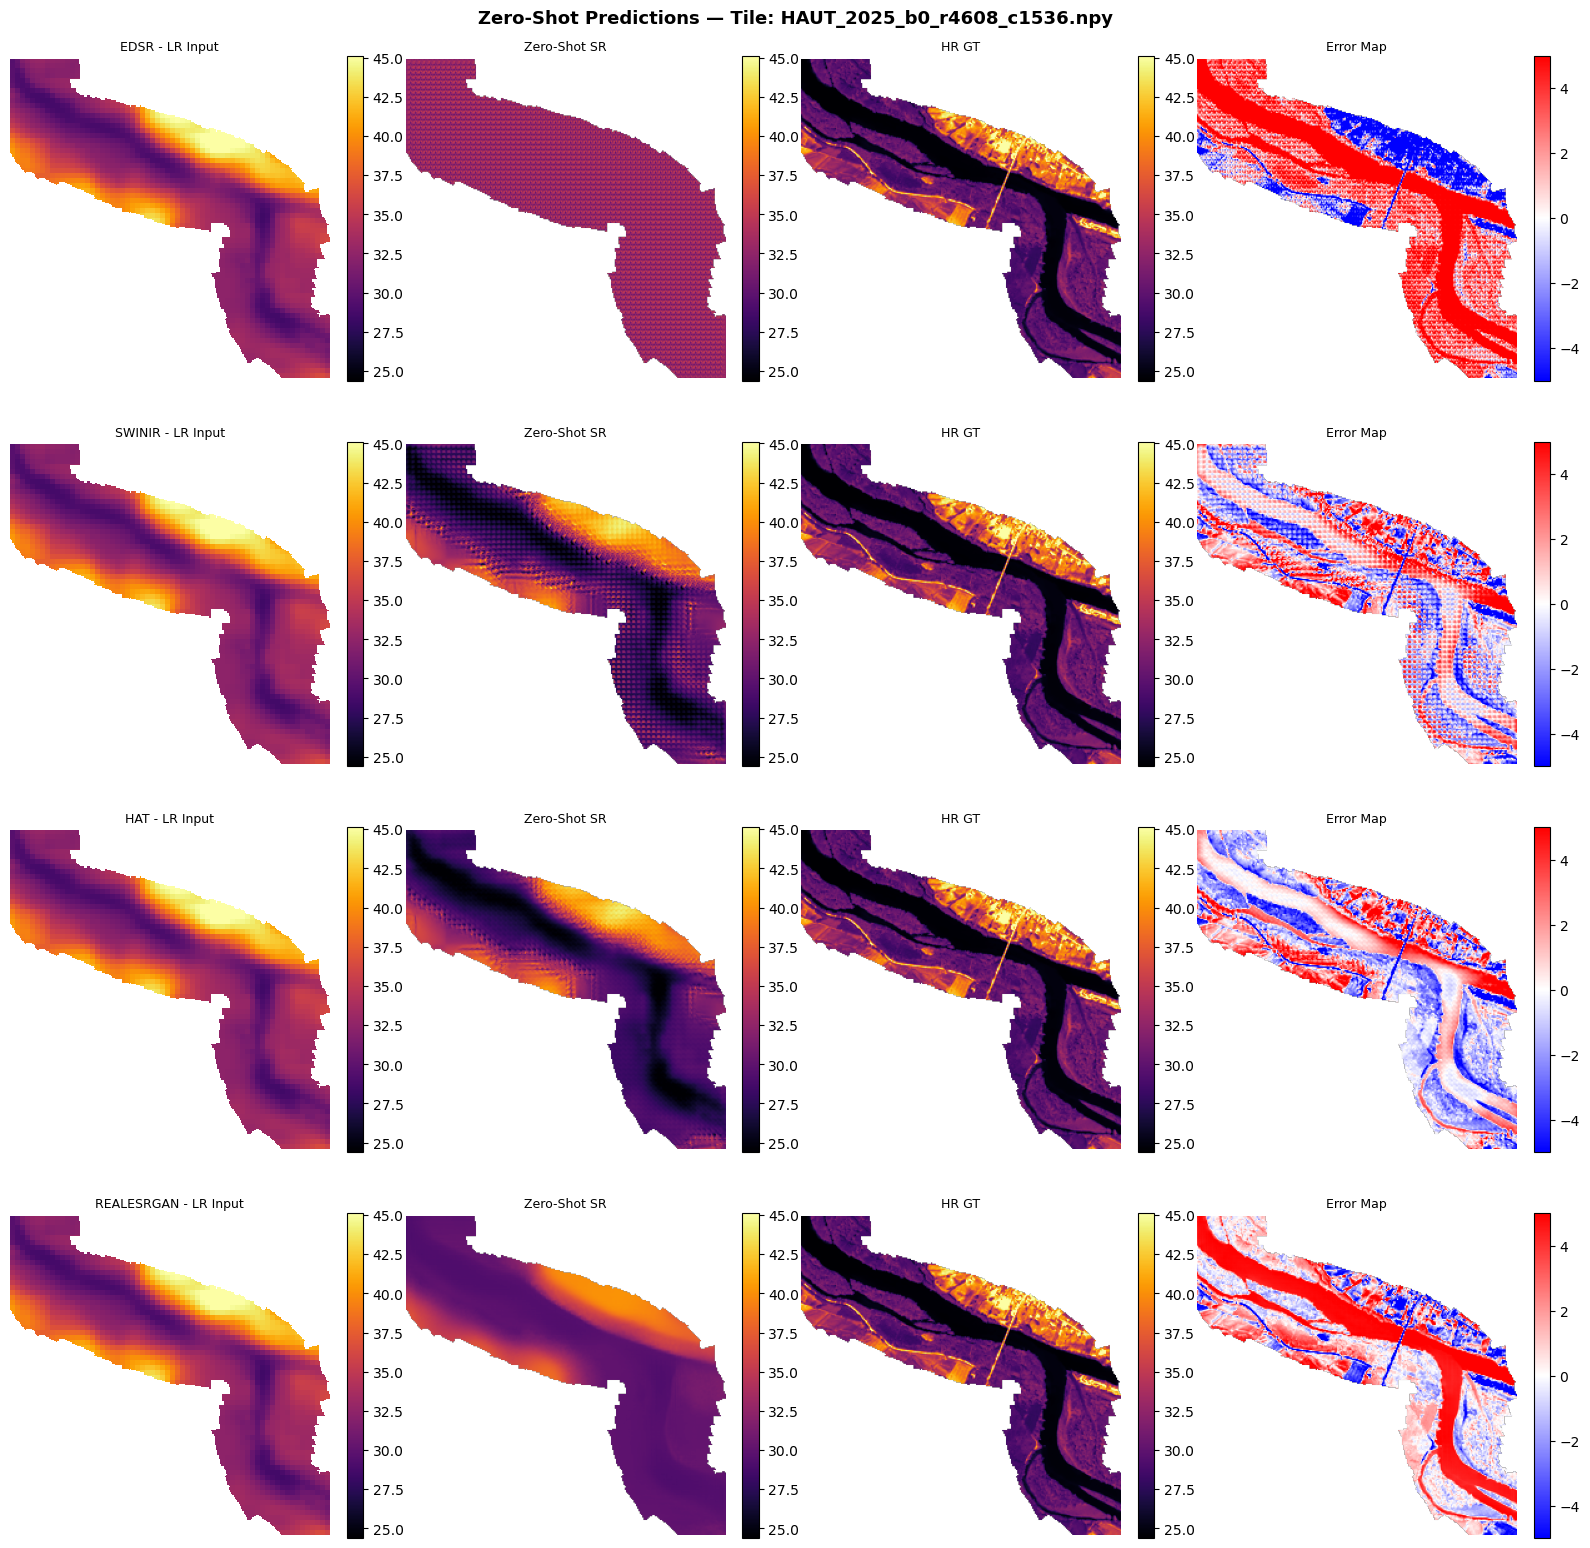

In [ ]:
for sample in samples:
    fname   = sample["fname"]
    hr_mask = sample["hr_mask"].squeeze().numpy()
    
    # Physical Temperature Conversion (°C)
    lr_64  = sample["lr"][0].numpy() * LR_STD + LR_MEAN
    lr_256 = np.repeat(np.repeat(lr_64, 4, axis=0), 4, axis=1) # Upsample for alignment
    lr_np  = np.where(hr_mask > 0.5, lr_256, np.nan)
    
    hr_np  = sample["hr"][0].numpy() * HR_STD + HR_MEAN
    hr_np  = np.where(hr_mask > 0.5, hr_np, np.nan)

    # Colorbar range from 1st to 99th percentile of valid pixels
    valid = hr_np[hr_mask > 0.5]
    vmin, vmax = np.nanpercentile(valid, 1), np.nanpercentile(valid, 99)

    fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(16, 4 * len(MODEL_NAMES)))
    fig.suptitle(f"Zero-Shot Predictions — Tile: {fname}", fontsize=13, fontweight="bold")

    for m_idx, model_name in enumerate(MODEL_NAMES):
        model_zi = loaded_pt_models[model_name]
        
        # Inference & Residual computation
        sr_np    = get_sr_pt(model_zi, sample)
        sr_np    = np.where(hr_mask > 0.5, sr_np, np.nan)
        residual = np.where(hr_mask > 0.5, sr_np - hr_np, np.nan)

        # 1. LR Input
        im0 = axes[m_idx, 0].imshow(lr_np, cmap="inferno", vmin=vmin, vmax=vmax, interpolation="nearest")
        axes[m_idx, 0].set_title(f"{model_name.upper()} - LR Input", fontsize=9)
        axes[m_idx, 0].axis("off")
        plt.colorbar(im0, ax=axes[m_idx, 0], fraction=0.046)

        # 2. SR Zero-Shot Output
        im1 = axes[m_idx, 1].imshow(sr_np, cmap="inferno", vmin=vmin, vmax=vmax)
        axes[m_idx, 1].set_title(f"Zero-Shot SR", fontsize=9)
        axes[m_idx, 1].axis("off")
        plt.colorbar(im1, ax=axes[m_idx, 1], fraction=0.046)

        # 3. Ground Truth HR
        im2 = axes[m_idx, 2].imshow(hr_np, cmap="inferno", vmin=vmin, vmax=vmax)
        axes[m_idx, 2].set_title("HR GT", fontsize=9)
        axes[m_idx, 2].axis("off")
        plt.colorbar(im2, ax=axes[m_idx, 2], fraction=0.046)

        # 4. Residual Error Map
        im3 = axes[m_idx, 3].imshow(residual, cmap="bwr", vmin=-5, vmax=5)
        axes[m_idx, 3].set_title("Error Map", fontsize=9)
        axes[m_idx, 3].axis("off")
        plt.colorbar(im3, ax=axes[m_idx, 3], fraction=0.046)

    plt.tight_layout()
    plt.show()

### Fine-tune

In [9]:
# Checkpoints and model names
CKPT_DIR    = SISR_ROOT / "checkpoints/phase2.1"

CHECKPOINTS = {
    "edsr":       CKPT_DIR / "edsr/edsr_phase2_epoch=59_val/water_mae=1.5755.ckpt",
    "swinir":     CKPT_DIR / "swinir/swinir_phase2_epoch=45_val/water_mae=1.2733.ckpt",
    "hat":        CKPT_DIR / "hat/hat_phase2_epoch=41_val/water_mae=1.3762.ckpt",
    "realesrgan": CKPT_DIR / "realesrgan/realesrgan_phase2_epoch=17_val/water_mae=1.5400.ckpt",
    "fastdiffsr":   CKPT_DIR / "fastdiffsr/fastdiffsr_phase2_epoch=20_val/water_mae=2.0117.ckpt",
    "diffbir":     CKPT_DIR / "diffbir/diffbir_phase2_epoch=22_val/water_mae=3.2109.ckpt"
}

In [10]:
loaded_ft_models = {}

common_kwargs = dict(
    hr_mean=HR_MEAN, hr_std=HR_STD,
    data_range=DATA_RANGE, data_min=DATA_MIN, phase=2
)

# Load fine-tuned models directly into memory (no testing loop)
for model_name in MODEL_NAMES:
    ckpt_path = CHECKPOINTS.get(model_name)
    
    if ckpt_path and ckpt_path.exists():
        print(f"[INFO] Loading FT {model_name.upper()} from: {ckpt_path.name}")
        cls = get_model_class(model_name)
        
        model_ft = cls.load_from_checkpoint(str(ckpt_path), strict=False, **common_kwargs)
        loaded_ft_models[model_name] = model_ft
    else:
        print(f"Warning: Checkpoint path not found for {model_name.upper()}: {ckpt_path}")

[INFO] Loading FT EDSR from: water_mae=1.5755.ckpt
[INFO] Loading EDSR pretrained: /share/home/e2406751/Superresolution-TIR/data/pretrained/EDSR_baseline_x4.pth
[INFO] Loaded 68/74 layers
[INFO] Loading FT SWINIR from: water_mae=1.2733.ckpt


/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/lightning/fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
/share/home/e2406751/.conda/envs/s

[INFO] Loading SwinIR pretrained: /share/home/e2406751/Superresolution-TIR/data/pretrained/SwinIR_classical_x4.pth
[INFO] Loaded 550/550 layers
[INFO] Loading FT HAT from: water_mae=1.3762.ckpt
[INFO] Loading HAT pretrained: /share/home/e2406751/Superresolution-TIR/data/pretrained/HAT_imagenet_x4.pth
[INFO] Loaded 864/864 layers
[INFO] Loading FT REALESRGAN from: water_mae=1.5400.ckpt
[INFO] Generator loaded
[INFO] Discriminator loaded


/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[INFO] Loading FT FASTDIFFSR from: water_mae=2.0117.ckpt
[FastDiffSR] Checkpoint loaded: 329 parameters; excluded 10 unused feature-extractor parameters.
[INFO] Loading FT DIFFBIR from: water_mae=3.2109.ckpt
[3, 3, 64, 23, 32, 4]
Setting up SDPCrossAttention (sdp). Query dim is 320, context_dim is None and using 5 heads.
Setting up SDPCrossAttention (sdp). Query dim is 320, context_dim is 1024 and using 5 heads.
Setting up SDPCrossAttention (sdp). Query dim is 320, context_dim is None and using 5 heads.
Setting up SDPCrossAttention (sdp). Query dim is 320, context_dim is 1024 and using 5 heads.
Setting up SDPCrossAttention (sdp). Query dim is 640, context_dim is None and using 10 heads.
Setting up SDPCrossAttention (sdp). Query dim is 640, context_dim is 1024 and using 10 heads.
Setting up SDPCrossAttention (sdp). Query dim is 640, context_dim is None and using 10 heads.
Setting up SDPCrossAttention (sdp). Query dim is 640, context_dim is 1024 and using 10 heads.
Setting up SDPCrossAtt

In [11]:
TARGET_TILES = ["HAUT_2025_b0_r1792_c3840.npy"]
# HAUT_2025_b0_r4608_c1536.npy #initial sample

samples = []
for idx in range(len(test_ds)):
    # Check if target name matches (handles with or without .npy extension)
    current_fname = str(test_ds[idx]["fname"])
    if any(target in current_fname for target in TARGET_TILES):
        samples.append(test_ds[idx])

if not samples:
    raise ValueError(f"None of the target tiles {TARGET_TILES} were found in test_ds!")

print(f"Selected tiles: {[s['fname'] for s in samples]}")

Selected tiles: ['HAUT_2025_b0_r1792_c3840.npy']


In [12]:
import torch.nn.functional as F

@torch.no_grad()
def get_sr_ft(model_name, sample):
    """Fine-tuned prediction from memory using model_name string."""
    model = loaded_ft_models[model_name]
    model.eval().to(device)

    lr = sample["lr"].unsqueeze(0).to(device)

    if model_name == "fastdiffsr":
        lr_c = model._to_physical(
            model._single_channel(lr), model.lr_mean, model.lr_std
        )
        lr_s = model._to_model_scale(lr_c)
        lr_up = F.interpolate(
            lr_s,
            size=(lr.shape[-2] * 4, lr.shape[-1] * 4),
            mode="bicubic",
            align_corners=False,
        )
        lr_up = lr_up.repeat(1, 3, 1, 1)
        sr_scaled = model(lr_up)
        sr = model._to_celsius(sr_scaled[:, 0:1])
        return sr.squeeze().cpu().numpy()

    if model_name == "diffbir":
        lr_z = model._single_channel(lr)
        lr_celsius = model._to_physical(
            lr_z, model.lr_mean, model.lr_std
        )
        lr01 = model._to_unit_interval(lr_celsius)
        lr01 = lr01.repeat(1, 3, 1, 1)
        sr01 = model(lr01)
        sr_celsius = model._to_celsius(sr01[:, 0:1])
        return sr_celsius.squeeze().cpu().numpy()

    sr = model(lr)
    return (sr[:, 0:1] * HR_STD + HR_MEAN).squeeze().cpu().numpy()

sampling loop time step:   0%|          | 0/20 [00:00<?, ?it/s]

sampling loop time step: 100%|██████████| 20/20 [00:00<00:00, 55.61it/s]


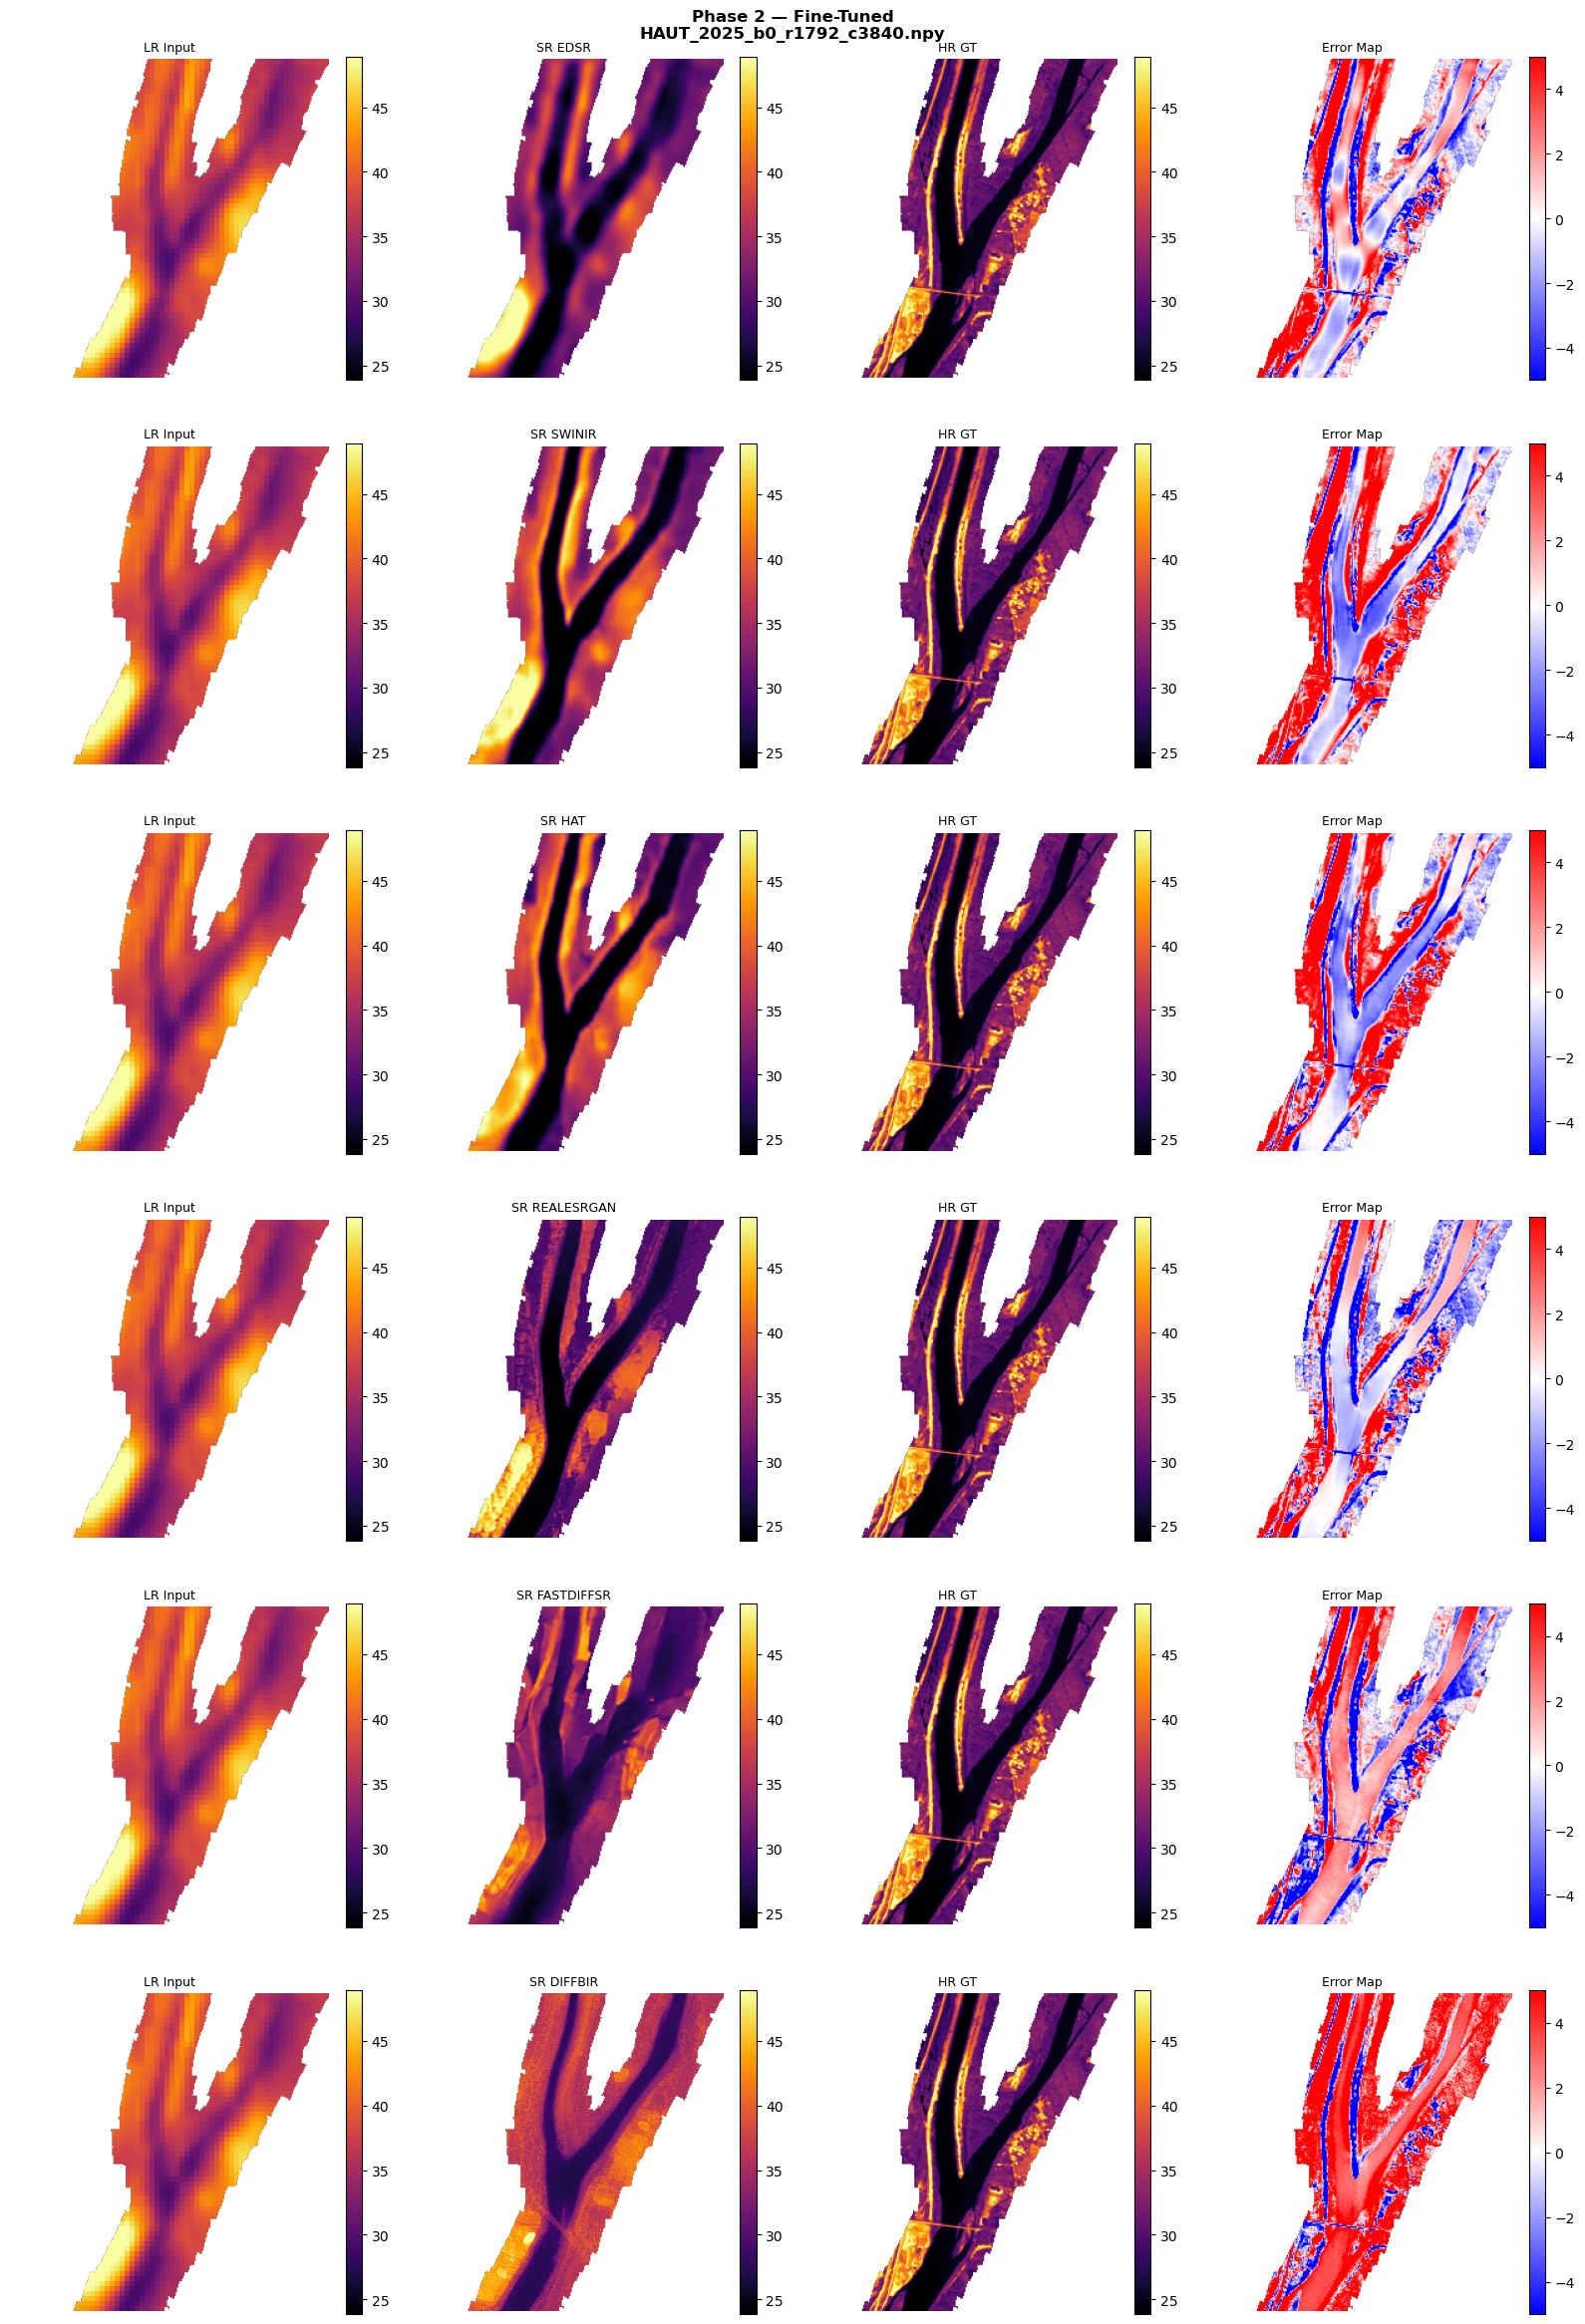

In [13]:
# Plot Phase 2 fine-tuned
# Columns: LR | SR | HR | Residual
for s_idx, sample in enumerate(samples):
    fname = sample["fname"]
    lr_np, hr_np, hr_mask, vmin, vmax = prep_sample(sample)

    fig, axes = plt.subplots(len(MODEL_NAMES), 4,
                             figsize=(16, 4 * len(MODEL_NAMES)))
    fig.suptitle(f"Phase 2 — Fine-Tuned\n{fname}",
                 fontsize=12, fontweight="bold")

    for m_idx, model_name in enumerate(MODEL_NAMES):
        sr_np    = get_sr_ft(model_name, sample)
        sr_np    = np.where(hr_mask > 0.5, sr_np, np.nan)
        residual = np.where(hr_mask > 0.5, sr_np - hr_np, np.nan)
        res_lim  = min(np.nanmax(np.abs(residual[hr_mask > 0.5])), 10) \
                   if np.isfinite(residual).any() else 5

        im = axes[m_idx, 0].imshow(lr_np, cmap="inferno", vmin=vmin, vmax=vmax)
        axes[m_idx, 0].set_title("LR Input", fontsize=9)
        axes[m_idx, 0].axis("off")
        plt.colorbar(im, ax=axes[m_idx, 0], fraction=0.046)

        im = axes[m_idx, 1].imshow(sr_np, cmap="inferno", vmin=vmin, vmax=vmax)
        axes[m_idx, 1].set_title(f"SR {model_name.upper()}", fontsize=9)
        axes[m_idx, 1].axis("off")
        plt.colorbar(im, ax=axes[m_idx, 1], fraction=0.046)

        im = axes[m_idx, 2].imshow(hr_np, cmap="inferno", vmin=vmin, vmax=vmax)
        axes[m_idx, 2].set_title("HR GT", fontsize=9)
        axes[m_idx, 2].axis("off")
        plt.colorbar(im, ax=axes[m_idx, 2], fraction=0.046)

        im = axes[m_idx, 3].imshow(residual, cmap="bwr",
                                   vmin=-5, vmax=5)
        axes[m_idx, 3].set_title(f"Error Map", fontsize=9)
        axes[m_idx, 3].axis("off")
        plt.colorbar(im, ax=axes[m_idx, 3], fraction=0.046)

    plt.tight_layout()
    plt.show()

sampling loop time step: 100%|██████████| 20/20 [00:00<00:00, 90.30it/s]


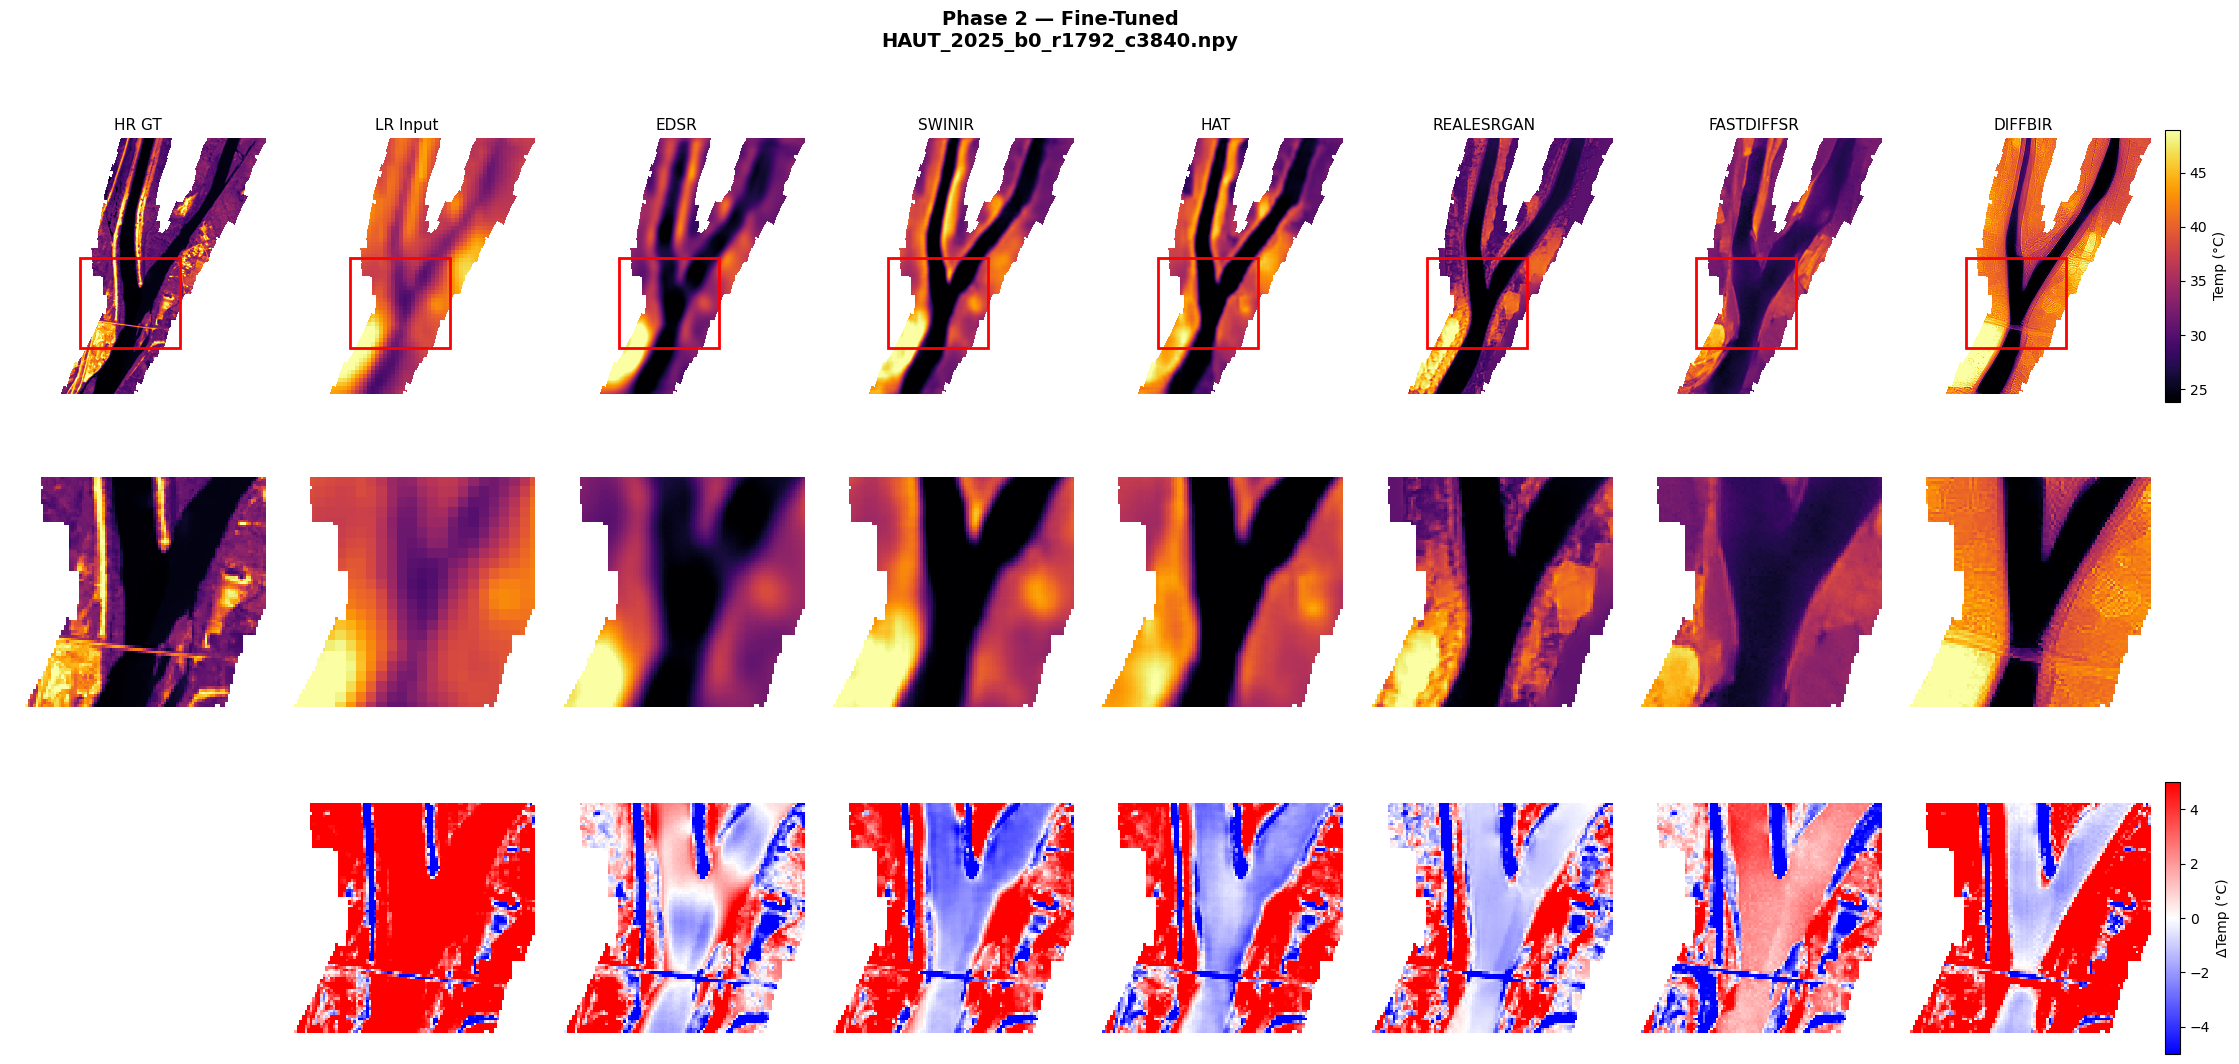

In [14]:
import os
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy.ndimage import zoom

x, y, w, h = 70, 120, 100, 90
row_slice = slice(y, y + h)
col_slice = slice(x, x + w)

def add_zoom_box(ax, x, y, w, h, color="red", lw=2):
    ax.add_patch(mpatches.Rectangle((x, y), w, h, linewidth=lw,
                                    edgecolor=color, facecolor="none"))

MODEL_NAMES = ["edsr", "swinir", "hat", "realesrgan", "fastdiffsr", "diffbir"]
COL_LABELS = ["HR GT", "LR Input"] + [m.upper() for m in MODEL_NAMES]
N_PANELS = len(COL_LABELS)          # 7
CBAR_COL = N_PANELS                 # 7 (the 8th column)

save_dir = "results/benchmark"
os.makedirs(save_dir, exist_ok=True)

for s_idx, sample in enumerate(samples):
    fname = sample["fname"]
    lr_np, hr_np, hr_mask, vmin, vmax = prep_sample(sample)

    # 1. Bicubic upsample of LR
    if lr_np.shape != hr_np.shape:
        zf = (hr_np.shape[0] / lr_np.shape[0], hr_np.shape[1] / lr_np.shape[1])
        lr_bicubic = zoom(lr_np, zf, order=3)
    else:
        lr_bicubic = lr_np.copy()
    lr_bicubic_masked = np.where(hr_mask > 0.5, lr_bicubic, np.nan)

    # 2. Model maps and residuals
    sr_maps, residuals = {}, {}
    residuals["bicubic"] = np.where(hr_mask > 0.5, lr_bicubic_masked - hr_np, np.nan)

    for model_name in MODEL_NAMES:
        torch.manual_seed(0)  # reproducible diffusion sampling
        sr_np = get_sr_ft(model_name, sample)
        sr_np = np.where(hr_mask > 0.5, sr_np, np.nan)
        sr_maps[model_name] = sr_np
        residuals[model_name] = np.where(hr_mask > 0.5, sr_np - hr_np, np.nan)

    full_panels = [hr_np, lr_bicubic_masked] + [sr_maps[m] for m in MODEL_NAMES]

    # 3. Plot
    fig = plt.figure(figsize=(28, 12))
    gs = gridspec.GridSpec(
        3, N_PANELS + 1,
        width_ratios=[1] * N_PANELS + [0.06],
        hspace=0.2, wspace=0.06, figure=fig,
    )
    fig.suptitle(f"Phase 2 — Fine-Tuned\n{fname}", fontsize=14, fontweight="bold")

    # Row 0: full patches
    for c, (label, arr) in enumerate(zip(COL_LABELS, full_panels)):
        ax = fig.add_subplot(gs[0, c])
        temp_im = ax.imshow(arr, cmap="inferno", vmin=vmin, vmax=vmax)
        ax.set_title(label, fontsize=11)
        ax.axis("off")
        add_zoom_box(ax, x, y, w, h)
    fig.colorbar(temp_im, cax=fig.add_subplot(gs[0, CBAR_COL]), label="Temp (°C)")

    # Row 1: zoomed crops
    for c, arr in enumerate(full_panels):
        ax = fig.add_subplot(gs[1, c])
        ax.imshow(arr[row_slice, col_slice], cmap="inferno",
                  vmin=vmin, vmax=vmax, interpolation="nearest")
        ax.axis("off")

    # Row 2: error maps
    fig.add_subplot(gs[2, 0]).axis("off")

    ax = fig.add_subplot(gs[2, 1])
    err_im = ax.imshow(residuals["bicubic"][row_slice, col_slice], cmap="bwr",
                       vmin=-5, vmax=5, interpolation="nearest")
    ax.axis("off")

    for i, model_name in enumerate(MODEL_NAMES):
        ax = fig.add_subplot(gs[2, 2 + i])
        err_im = ax.imshow(residuals[model_name][row_slice, col_slice], cmap="bwr",
                           vmin=-5, vmax=5, interpolation="nearest")
        ax.axis("off")
    fig.colorbar(err_im, cax=fig.add_subplot(gs[2, CBAR_COL]), label="ΔTemp (°C)")

    plt.show()
    plt.close(fig)

### Difference maps

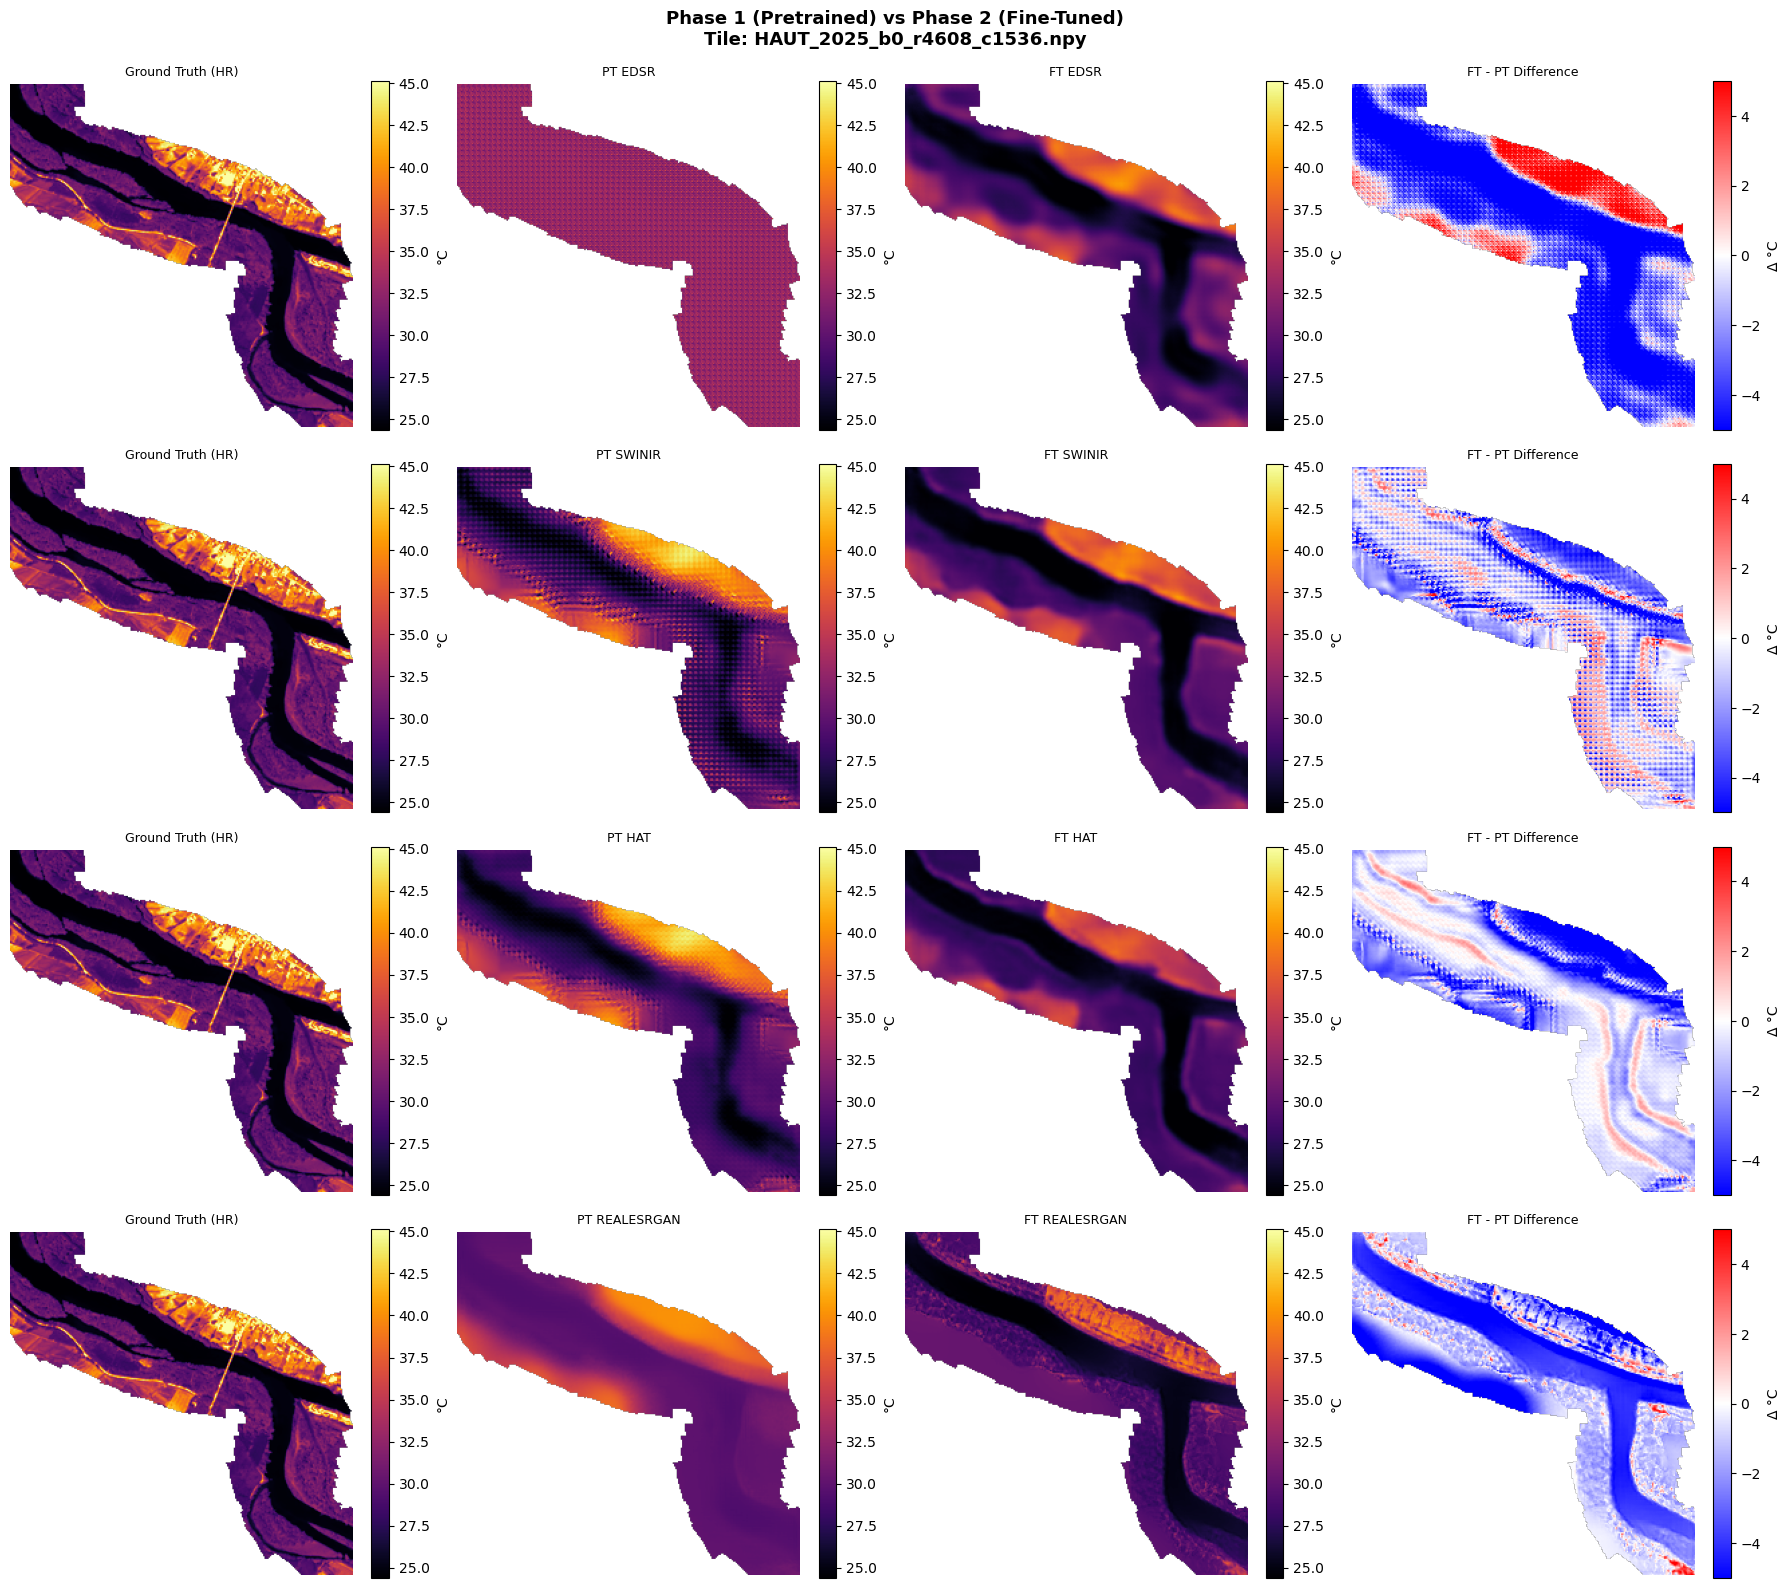

In [19]:
for sample in samples:
    fname   = sample["fname"]
    lr_np, hr_np, hr_mask, vmin, vmax = prep_sample(sample)

    fig, axes = plt.subplots(len(MODEL_NAMES), 4, figsize=(18, 4 * len(MODEL_NAMES)))
    fig.suptitle(f"Phase 1 (Pretrained) vs Phase 2 (Fine-Tuned)\nTile: {fname}", 
                 fontsize=13, fontweight="bold", y=0.99)

    for m_idx, model_name in enumerate(MODEL_NAMES):
        # 1. Zero-shot prediction (PT)
        sr_pt = get_sr_pt(model_name, sample)
        sr_pt = np.where(hr_mask > 0.5, sr_pt, np.nan)

        # 2. Fine-tuned prediction (FT)
        sr_ft = get_sr_ft(model_name, sample)
        sr_ft = np.where(hr_mask > 0.5, sr_ft, np.nan)

        # 3. Difference map (FT - PT)
        diff = np.where(hr_mask > 0.5, sr_ft - sr_pt, np.nan)
        diff_lim = min(np.nanmax(np.abs(diff[hr_mask > 0.5])), 5.0) if np.isfinite(diff).any() else 2.0

        # Col 0 — Ground Truth HR
        im0 = axes[m_idx, 0].imshow(hr_np, cmap="inferno", vmin=vmin, vmax=vmax)
        axes[m_idx, 0].set_title("Ground Truth (HR)", fontsize=9)
        axes[m_idx, 0].axis("off")
        plt.colorbar(im0, ax=axes[m_idx, 0], fraction=0.046, label="°C")

        # Col 1 — Pretrained SR
        im1 = axes[m_idx, 1].imshow(sr_pt, cmap="inferno", vmin=vmin, vmax=vmax)
        axes[m_idx, 1].set_title(f"PT {model_name.upper()}", fontsize=9)
        axes[m_idx, 1].axis("off")
        plt.colorbar(im1, ax=axes[m_idx, 1], fraction=0.046, label="°C")

        # Col 2 — Fine-Tuned SR
        im2 = axes[m_idx, 2].imshow(sr_ft, cmap="inferno", vmin=vmin, vmax=vmax)
        axes[m_idx, 2].set_title(f"FT {model_name.upper()}", fontsize=9)
        axes[m_idx, 2].axis("off")
        plt.colorbar(im2, ax=axes[m_idx, 2], fraction=0.046, label="°C")

        # Col 3 — Difference Map (FT - PT)
        im3 = axes[m_idx, 3].imshow(diff, cmap="bwr", vmin=-diff_lim, vmax=diff_lim)
        axes[m_idx, 3].set_title("FT - PT Difference", fontsize=9)
        axes[m_idx, 3].axis("off")
        plt.colorbar(im3, ax=axes[m_idx, 3], fraction=0.046, label="Δ °C")

    plt.tight_layout()
    plt.show()

### STATS

In [3]:
from scripts.models.realesrgan import RealESRGANModule

MODEL_PATH  = str(BASE / "checkpoints/phase2.1/realesrgan/realesrgan_phase2_epoch=17_val/water_mae=1.5400.ckpt")
model = RealESRGANModule.load_from_checkpoint(MODEL_PATH, strict=False).to(device).eval()

/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/lightning/fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


[INFO] Generator loaded
[INFO] Discriminator loaded


/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/share/home/e2406751/.conda/envs/sisr/lib/python3.11/site-packages/lightning/pytorch/core/saving.py:197: Found keys that are not in the model state dict but in the checkpoint: ['lpips_fn.net.net.slice1.0.weight', 'lpips_fn.net.net.slice1.0.bias', 'lpips_fn.net.net.slice1.2.weight', 'lpips_fn.net.net.slice1.2.bias', 'lpips_fn.ne

In [4]:
def run_inference(model_obj, sample):
    lr = sample["lr"].unsqueeze(0).to(device)

    with torch.no_grad():
        sr = model_obj(lr)

    return (sr[:, 0] * HR_STD + HR_MEAN).squeeze().cpu().numpy()

### CDF

In [4]:
import numpy as np
import pandas as pd

def extract_water_pixels(dataset, model_obj, model_name="Baseline", save_path=None):
    all_hr, all_lr, all_sr, all_residuals, all_sample_ids = [], [], [], [], []

    for idx, sample in enumerate(dataset):
        hr_mask = sample["hr_mask"].squeeze(0)
        water_mask = sample["water_mask"].squeeze(0)

        pure_water = (hr_mask > 0.5) & (water_mask > 0.5)
        if pure_water.sum() < 10:
            continue

        sr_np = run_inference(model_obj, sample)

        # Denormalize TIR channels
        hr_np = (sample["hr"][0].numpy() * HR_STD) + HR_MEAN
        lr_np = (sample["lr"][0].numpy() * LR_STD) + LR_MEAN

        # Upscale LR TIR to match HR/SR grid
        lr_up = np.repeat(np.repeat(lr_np, 4, axis=0), 4, axis=1)

        pure_water = pure_water.numpy()
        valid = (pure_water & np.isfinite(hr_np) & np.isfinite(sr_np) & np.isfinite(lr_up))
        if valid.sum() == 0:
            continue

        hr_water = hr_np[valid]
        lr_water = lr_up[valid]
        sr_water = sr_np[valid]
        residual = sr_water - hr_water

        all_hr.append(hr_water)
        all_lr.append(lr_water)
        all_sr.append(sr_water)
        all_residuals.append(residual)
        all_sample_ids.extend([idx] * len(residual))

    # Flatten into 1D NumPy arrays
    sample_ids_v = np.array(all_sample_ids)
    hr_v = np.concatenate(all_hr)
    lr_v = np.concatenate(all_lr)
    sr_v = np.concatenate(all_sr)
    residual_v = np.concatenate(all_residuals)

    # File path handling
    if save_path is None:
        save_path = f"water_pixels_{model_name.lower().replace(' ', '_')}.npz"

    # Save to compressed NPZ
    np.savez_compressed(
        save_path,
        sample_id=sample_ids_v,
        hr_temp=hr_v,
        lr_temp=lr_v,
        sr_temp=sr_v,
        residual=residual_v,
        model_name=model_name
    )
    
    print(f"Saved {len(residual_v):,} water pixels to {save_path}")

    # Return a DataFrame for immediate plotting if needed
    return pd.DataFrame({
        "sample_id": sample_ids_v,
        "hr_temp": hr_v,
        "lr_temp": lr_v,
        "sr_temp": sr_v,
        "residual": residual_v,
        "model": model_name
    })

In [ ]:
baseline_df = extract_water_pixels(
    dataset=test_ds,
    model_obj=model,
    model_name="Baseline",
    save_path="base_wt_px.npz"
)

Saved 440,308 water pixels to water_pixels_baseline.npz


In [6]:
# Access array shapes directly from DataFrame columns
print("HR shape:", baseline_df["hr_temp"].shape)
print("LR shape:", baseline_df["lr_temp"].shape)
print("SR shape:", baseline_df["sr_temp"].shape)

print("\nResidual dataframe:")
print(baseline_df["residual"].head())

print("\nResidual statistics:")
print(baseline_df["residual"].describe())

HR shape: (440308,)
LR shape: (440308,)
SR shape: (440308,)

Residual dataframe:
0    1.284714
1    2.353441
2    1.505215
3    1.733780
4    1.786501
Name: residual, dtype: float32

Residual statistics:
count    440308.000000
mean          1.674076
std           3.234496
min         -47.869213
25%          -0.000986
50%           1.239504
75%           3.223980
max          29.386023
Name: residual, dtype: float64


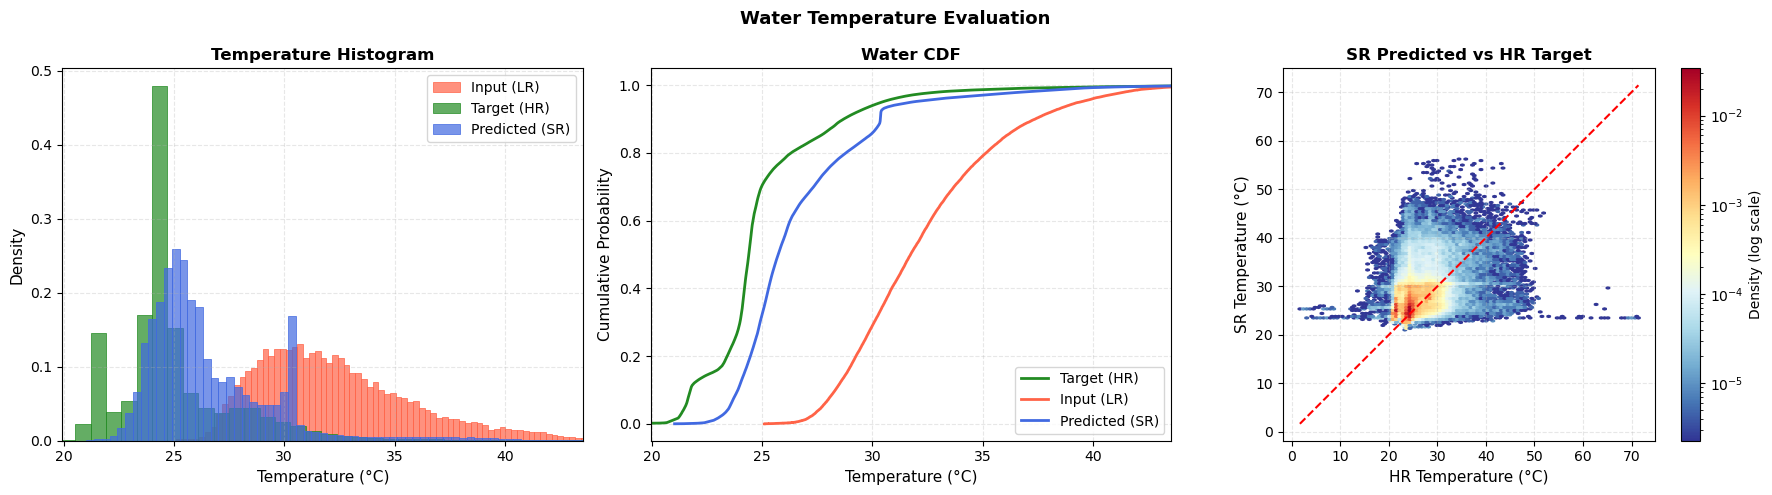

In [7]:
# --- Common Limits for Histogram and CDF ---
padding = 1.0  
xmin = np.percentile(baseline_df["hr_temp"], 1) - padding
xmax = np.percentile(baseline_df["lr_temp"], 99) + padding

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Water Temperature Evaluation", fontsize=13, fontweight="bold")

# Palette setup
palette = {"HR": "forestgreen", "SR": "royalblue", "LR": "tomato"}

# ---------------- Panel 1: Histogram + KDE ----------------
ax_hist = axes[0]
# Plotting order: Input (LR) background, Target (HR) and Predicted (SR) foreground
for vec, key, lbl in [(baseline_df["lr_temp"], "LR", "Input (LR)"), 
                      (baseline_df["hr_temp"], "HR", "Target (HR)"), 
                      (baseline_df["sr_temp"], "SR", "Predicted (SR)")]:
    
    sns.histplot(
        vec,
        ax=ax_hist,
        bins=100,
        stat="density",              
        kde=False,                  # ← Automatically scales the KDE line to match Pixel Counts!
        color=palette[key],
        label=lbl,
        alpha=0.7,                # Soft bar shading
        edgecolor=palette[key],        
        linewidth=0.5,
        line_kws={"linewidth": 1.0}  # Smooth KDE curve thickness
    )

ax_hist.set_title("Temperature Histogram", fontsize=12, fontweight="bold")
ax_hist.set_xlabel("Temperature (°C)", fontsize=11)
ax_hist.set_ylabel("Density", fontsize=11)            # Raw pixel count
ax_hist.set_xlim(xmin, xmax)
ax_hist.grid(True, linestyle="--", alpha=0.3)
ax_hist.legend(loc="upper right", frameon=True)

# ---------------- Panel 2: Water CDF ----------------
ax_cdf = axes[1]
for vec, key, lbl in [(baseline_df["hr_temp"], "HR", "Target (HR)"), 
                      (baseline_df["lr_temp"], "LR", "Input (LR)"),
                      (baseline_df["sr_temp"], "SR", "Predicted (SR)")]:
    
    sorted_data = np.sort(vec)
    y_values = np.arange(1, len(sorted_data) + 1) / len(sorted_data)
    ax_cdf.plot(sorted_data, y_values, color=palette[key], lw=2.0, label=lbl)

ax_cdf.set_title("Water CDF", fontsize=12, fontweight="bold")
ax_cdf.set_xlabel("Temperature (°C)", fontsize=11)
ax_cdf.set_ylabel("Cumulative Probability", fontsize=11)
ax_cdf.set_xlim(xmin, xmax) 
ax_cdf.grid(True, linestyle="--", alpha=0.3)
ax_cdf.legend(loc="lower right", frameon=True)

# ---------------- Panel 3: Hexbin (1:1 Scatter) ----------------
from matplotlib.colors import LogNorm

ax_scat = axes[2]
weights = np.ones_like(baseline_df["hr_temp"]) / len(baseline_df["hr_temp"])
hb = ax_scat.hexbin(
    baseline_df["hr_temp"], baseline_df["sr_temp"],
    C=weights, reduce_C_function=np.sum,
    gridsize=100,
    cmap="RdYlBu_r",
    mincnt=1,
    norm=LogNorm(),   
)

temp_min, temp_max = min(baseline_df["hr_temp"].min(), baseline_df["sr_temp"].min()), max(baseline_df["hr_temp"].max(), baseline_df["sr_temp"].max())  # renamed, was global_min/max
ax_scat.plot([temp_min, temp_max], [temp_min, temp_max], "r--", lw=1.5)

ax_scat.set_title("SR Predicted vs HR Target", fontsize=12, fontweight="bold")
ax_scat.set_xlabel("HR Temperature (°C)", fontsize=11)
ax_scat.set_ylabel("SR Temperature (°C)", fontsize=11)
ax_scat.set_aspect("equal")
ax_scat.grid(True, linestyle="--", alpha=0.3)
fig.colorbar(hb, ax=ax_scat, label="Density (log scale)")

plt.tight_layout()
# plt.savefig(
#         "stats_fig_base.png", dpi=600, bbox_inches="tight", pad_inches=0
#     )
plt.show()

### Residuals

In [5]:
def extract_residuals(dataset, model_obj, region="water", model_name="Baseline", save_path=None):
    all_residuals = []
    all_sample_ids = []

    for idx, sample in enumerate(dataset):
        hr_mask = sample["hr_mask"].squeeze(0)
        water_mask = sample["water_mask"].squeeze(0)

        # -----------------------------
        # Region mask
        # -----------------------------
        if region == "water":
            region_mask = (hr_mask > 0.5) & (water_mask > 0.5)
        elif region == "non_water":
            region_mask = (hr_mask > 0.5) & (water_mask <= 0.5)
        else:
            raise ValueError("region must be 'water' or 'non_water'")

        if region_mask.sum() < 10:
            continue

        # Model inference
        sr_np = run_inference(model_obj, sample)

        # Denormalize HR
        hr_np = ( sample["hr"][0].numpy() * HR_STD) + HR_MEAN

        # Valid pixels
        region_mask = region_mask.numpy()
        valid = ( region_mask & np.isfinite(hr_np) & np.isfinite(sr_np))

        if valid.sum() == 0:
            continue

        # Residual
        residual = sr_np[valid] - hr_np[valid]

        all_residuals.append(residual)
        all_sample_ids.extend([idx] * len(residual))

    # Flatten
    residual_v = np.concatenate(all_residuals)
    sample_ids_v = np.array(all_sample_ids)

    # Save
    if save_path is None: save_path = ( f"{region}_residuals_" f"{model_name.lower().replace(' ', '_')}.npz")

    np.savez_compressed(
        save_path,
        sample_id=sample_ids_v,
        residual=residual_v,
        model_name=model_name,
        region=region
    )

    print(f"Saved {len(residual_v):,} " f"{region} residuals for {model_name}")

    return pd.DataFrame({
        "sample_id": sample_ids_v,
        "residual": residual_v,
        "model": model_name,
        "region": region
    })

In [6]:
baseline_water = extract_residuals(
    test_ds,
    model,
    region="water",
    model_name="baseline",
    save_path="base_wt_res.npz"
)

baseline_nonwater = extract_residuals(
    test_ds,
    model,
    region="non_water",
    model_name="baseline",
    save_path="base_nw_res.npz"
)

Saved 440,308 water residuals for baseline
Saved 935,467 non_water residuals for baseline
